In [11]:
#import the library's that will be used
import eurostat
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
#this class will help import the data from eurostat and to check the data's parameters, columns, etc
class EuroStatExplorer:
    def __init__(self):
        self.toc_df = eurostat.get_toc_df()
        self.raw_data = None

    def search_dataset(self, keyword):
        return eurostat.subset_toc_df(self.toc_df, keyword)

    def get_parameters(self, dataset_code):
        return eurostat.get_pars(dataset_code)

    def load_dataset(self, dataset_code):
        self.raw_data = eurostat.get_data_df(dataset_code)
        return self.raw_data

    def inspect_dataset(self):
        if self.raw_data is None:
            raise ValueError("Load a dataset before inspecting it.")
        print("Shape:", self.raw_data.shape)
        print("Columns:", self.raw_data.columns.tolist())
        print("Data types:")
        print(self.raw_data.dtypes)
        print("First observations:")
        print(self.raw_data.head())

In [13]:
es = EuroStatExplorer()

In [14]:
#retrieve data from eurostat and checking its parameters
print(es.get_parameters("mar_mg_aa_cwh"))  
dataset1 = es.load_dataset("mar_mg_aa_cwh")
es.inspect_dataset()

['freq', 'unit', 'rep_mar']
Shape: (99, 31)
Columns: ['freq', 'unit', 'rep_mar\\TIME_PERIOD', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']
Data types:
freq                       str
unit                       str
rep_mar\TIME_PERIOD        str
1997                   float64
1998                   float64
1999                   float64
2000                   float64
2001                   float64
2002                   float64
2003                   float64
2004                   float64
2005                   float64
2006                   float64
2007                   float64
2008                   float64
2009                   float64
2010                   float64
2011                   float64
2012                   float64
2013                   float64
2014                   float64
2015               

In [15]:
#transposing the data to have the countries as columns and the years as rows
transposed_dataset1 = dataset1.T

dataset1_df = transposed_dataset1.loc["2014":"2024"].copy()   
dataset1_df.columns = transposed_dataset1.iloc[2].tolist()    
print(dataset1_df)

       BE    BG    CY   DE   DK    EE EEA31   EL   ES EU15  ...    MT    NL    NO   PL   PT   RO    SE    SI   TR   UK
2014  4.3  -5.6   0.2  2.2  4.3   1.6   1.6  4.7  7.6  1.8  ...   8.0  33.9  39.1  1.8  7.7  2.2  17.3   8.7  4.9  7.8
2015  1.5  -0.3  42.9 -2.6  3.1 -19.8   0.9 -0.9  4.5  1.4  ...   8.3  34.7  37.3  1.8  8.4  2.2  17.3   9.7  5.3  7.6
2016  5.0   5.6  -0.1  0.4  0.8  -3.9   0.6  4.8  0.9  0.5  ...   8.3  34.1  38.2  1.9  8.8  2.3  17.3  10.3  5.4  7.4
2017  1.7   7.9 -23.4  0.7 -1.2   3.6   2.8  3.5  7.2  2.6  ...   8.8  34.6  39.9  2.1  9.1  2.4  17.5  10.8  5.8  7.3
2018  4.8 -10.0 -11.6 -1.0  1.4   3.3   2.7  5.1  2.9  2.4  ...   9.4  34.8  40.6  2.4  8.8  2.5  17.7  11.2  5.6  7.3
2019  2.8  11.2   6.9 -0.6 -2.4   5.0   0.0  2.1 -0.2  0.0  ...  10.3  34.8  39.5  2.5  8.2  2.7  16.6  10.6  5.8  7.3
2020 -3.3 -18.5   0.6 -6.4 -2.5   0.0   NaN -8.3 -8.3  NaN  ...  11.1  31.4  41.4  2.4  7.7  2.5  16.3   8.7  5.9  NaN
2021  7.5   1.3  -6.5  4.9  3.1   4.5   NaN -0.1

In [16]:
#naming lists that will  be used to make the graphs
countries = ["PT", "NL", "IT"]
NAMES = {"PT": "Portugal", "NL": "Netherlands", "IT": "Italy"}
COLOR_MAP = {"PT": "#6696b3", "NL": "#d2a071", "IT": "#69a89d"}


In [17]:
#separating the data by unit for the three countries
units = transposed_dataset1.loc["unit"].to_numpy()

def select_unit(unit):
    columns = (units == unit) & dataset1_df.columns.isin(countries)
    return dataset1_df.loc[:, columns].apply(pd.to_numeric)

dataset1_thousandTonnes = select_unit("THS_T")   
dataset1_tonnesPerCapita = select_unit("T_HAB")  
dataset1_growthRate = select_unit("RT_PRE")    

print("Thousand tonnes")
print(dataset1_thousandTonnes, "\n")
print("Tonnes per inhabitant")
print(dataset1_tonnesPerCapita, "\n")
print("Growth rate on previous year (%)")
print(dataset1_growthRate)

Thousand tonnes
            IT        NL       PT
2014  443141.0  571636.0  80156.0
2015  458020.0  588506.0  86769.0
2016  461990.0  581070.0  91344.0
2017  475164.0  593489.0  93356.0
2018  501958.0  599843.0  90361.0
2019  508074.0  602821.0  85320.0
2020  469635.0  547758.0  79371.0
2021  501603.0  580179.0  83080.0
2022  509397.0  589935.0  85025.0
2023  488888.0  545105.0  82110.0
2024  488556.0  538120.0  85669.0 

Tonnes per inhabitant
       IT    NL   PT
2014  7.3  33.9  7.7
2015  7.5  34.7  8.4
2016  7.6  34.1  8.8
2017  7.8  34.6  9.1
2018  8.3  34.8  8.8
2019  8.5  34.8  8.2
2020  7.9  31.4  7.7
2021  8.5  33.1  8.0
2022  8.6  33.3  8.2
2023  8.3  30.5  7.8
2024  8.3  29.9  8.0 

Growth rate on previous year (%)
       IT   NL   PT
2014 -3.0  2.3  2.4
2015  3.4  3.0  8.2
2016  0.9 -1.3  5.3
2017  2.9  2.1  2.2
2018  5.6  1.1 -3.2
2019  1.2  0.5 -5.6
2020 -7.6 -9.1 -7.0
2021  6.8  5.9  4.7
2022  1.6  1.7  2.3
2023 -4.0 -7.6 -3.4
2024 -0.1 -1.3  4.3


In [18]:
#preparing  tables for analisys and getting the EU27 values to compare
colors = [COLOR_MAP[c] for c in countries]   
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

def prep(df):
    t = df.copy()
    t.index = t.index.astype(int)
    t.index.name = "year"
    return t[countries]

tonnes = prep(dataset1_thousandTonnes)    
per_cap = prep(dataset1_tonnesPerCapita) 
growth = prep(dataset1_growthRate)        

def eu_series(unit):
    cols = (units == unit) & (dataset1_df.columns == "EU27_2020")
    if not cols.any():
        return None
    s = dataset1_df.loc[:, cols].apply(pd.to_numeric).iloc[:, 0]
    s.index = s.index.astype(int)
    return s

eu = eu_series("THS_T")
eu_per_cap = eu_series("T_HAB")
#checking if the eurostat growth rate is the same as our own calculation
check = (tonnes.pct_change(fill_method=None) * 100).round(1) - growth
print("Largest difference between RT_PRE and our own calculation (2015–2024):",
      check.loc[2015:].abs().max().round(1).to_dict())

Largest difference between RT_PRE and our own calculation (2015–2024): {'PT': 0.1, 'NL': 0.0, 'IT': 0.0}


In [19]:
#making the tables Goods handled in all ports and Share of the EU27 tonnage handled in ports 
#with the size, change and share of the EU27 of each country
YEAR = 2024
table1 = pd.DataFrame({
    "million tonnes 2024": tonnes.loc[YEAR] / 1000,
    "change 2014–2024 (%)": (tonnes.loc[YEAR] / tonnes.loc[2014] - 1) * 100,
    "average annual growth (%)": ((tonnes.loc[YEAR] / tonnes.loc[2014]) ** (1 / 10) - 1) * 100,
    "peak year": tonnes.idxmax(),
    "peak (million tonnes)": tonnes.max() / 1000,
    "lowest year": tonnes.idxmin(),
}).round(1).rename(index=NAMES)

if eu is None:
    print("No EU27_2020 column in dataset1: the EU27 shares need it.")
else:
    table1.insert(1, "share of EU27 2024 (%)", (tonnes.loc[YEAR] / eu.loc[YEAR] * 100).rename(NAMES).round(1))
print(table1)

if eu is not None:
    print(f"The three countries together: {tonnes.loc[YEAR].sum() / eu.loc[YEAR] * 100:.1f}% of EU27 tonnage in {YEAR}")
    print("\nShare of EU27 tonnage over time (%)")
    print((tonnes.div(eu, axis=0) * 100).rename(columns=NAMES).round(1))

             million tonnes 2024  share of EU27 2024 (%)  change 2014–2024 (%)  average annual growth (%)  peak year  peak (million tonnes)  lowest year
Portugal                    85.7                     2.6                   6.9                        0.7       2017                   93.4         2020
Netherlands                538.1                    16.0                  -5.9                       -0.6       2019                  602.8         2024
Italy                      488.6                    14.6                  10.2                        1.0       2022                  509.4         2014
The three countries together: 33.1% of EU27 tonnage in 2024

Share of EU27 tonnage over time (%)
      Portugal  Netherlands  Italy
year                              
2014       2.4         17.4   13.5
2015       2.6         17.6   13.7
2016       2.7         17.2   13.7
2017       2.7         17.1   13.7
2018       2.5         16.8   14.0
2019       2.4         16.8   14.2
2020       

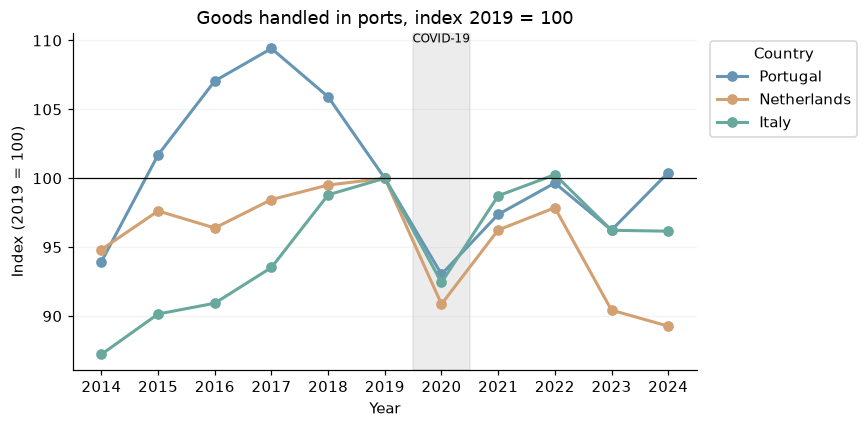

Back to the 2019 level in: {'Portugal': 2024, 'Netherlands': 'not by 2024', 'Italy': 2022}
         PT     NL     IT
year                     
2014   93.9   94.8   87.2
2015  101.7   97.6   90.1
2016  107.1   96.4   90.9
2017  109.4   98.5   93.5
2018  105.9   99.5   98.8
2019  100.0  100.0  100.0
2020   93.0   90.9   92.4
2021   97.4   96.2   98.7
2022   99.7   97.9  100.3
2023   96.2   90.4   96.2
2024  100.4   89.3   96.2


In [20]:
#making  a Goods handled in ports with the index (2019 = 100) graph to compare the three countries in the same scale
BASE_YEAR = 2019
index = tonnes / tonnes.loc[BASE_YEAR] * 100

fig, ax = plt.subplots(figsize=(8, 4))
for c in countries:
    ax.plot(index.index, index[c], marker="o", linewidth=2, color=COLOR_MAP[c], label=NAMES[c])
ax.axhline(100, color="black", linewidth=0.8)
ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15)
ax.text(2020, ax.get_ylim()[1], "COVID-19", ha="center", va="top", fontsize=8)
ax.set(title=f"Goods handled in ports, index {BASE_YEAR} = 100", xlabel="Year", ylabel=f"Index ({BASE_YEAR} = 100)")
ax.set_xticks(index.index)
ax.grid(axis="y", alpha=0.15)
ax.legend(title="Country", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

#checking in which year each country got back to the 2019 level
recovery = {NAMES[c]: next((y for y in tonnes.index if y > 2020 and tonnes.loc[y, c] >= tonnes.loc[2019, c]),
                           "not by 2024") for c in countries}
print("Back to the 2019 level in:", recovery)
print(index.round(1))

In [21]:
#growth rates in the years of the main shocks and how much they vary in each country
print("Growth rate on previous year (%), shock years")
print(growth.loc[[2020, 2021, 2023, 2024]].rename(columns=NAMES))

print("\nStandard deviation of growth rates, 2014–2024 (percentage points):",
      growth.std().round(1).rename(NAMES).to_dict())

Growth rate on previous year (%), shock years
      Portugal  Netherlands  Italy
year                              
2020      -7.0         -9.1   -7.6
2021       4.7          5.9    6.8
2023      -3.4         -7.6   -4.0
2024       4.3         -1.3   -0.1

Standard deviation of growth rates, 2014–2024 (percentage points): {'Portugal': 4.9, 'Netherlands': 4.5, 'Italy': 4.2}


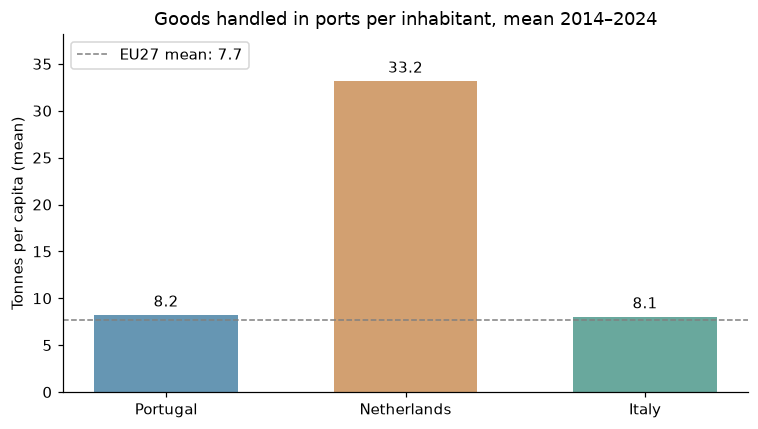

        Portugal  Netherlands  Italy
mean         8.2         33.2    8.1
median       8.2         33.9    8.3
std          0.5          1.8    0.5
min          7.7         29.9    7.3
max          9.1         34.8    8.6
cv (%)       5.8          5.4    5.6


In [22]:
#making a graph with the goods handled per inhabitant with mean 2014–2024 compared with the EU27 average
STAT = "mean"   
values = per_cap.agg(STAT).rename(NAMES)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(values.index, values.values, color=colors, width=0.6)
ax.bar_label(bars, fmt="%.1f", padding=3)
if eu_per_cap is not None:
    eu_value = eu_per_cap.agg(STAT)
    ax.axhline(eu_value, color="grey", linestyle="--", linewidth=1, label=f"EU27 {STAT}: {eu_value:.1f}")
    ax.legend(loc="upper left")
ax.set(title=f"Goods handled in ports per inhabitant, {STAT} 2014–2024",
       ylabel=f"Tonnes per capita ({STAT})", ylim=(0, values.max() * 1.15))
plt.tight_layout()
plt.show()
#statistics of the tonnes per inhabitant, the cv shows the variation relative to each country's level
stats = per_cap.agg(["mean", "median", "std", "min", "max"])
stats.loc["cv (%)"] = stats.loc["std"] / stats.loc["mean"] * 100
print(stats.rename(columns=NAMES).round(1))